In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("welcome to employee turnover analysis")

welcome to employee turnover analysis


In [5]:
#reading excel sheet and name of sheet is sheet1

df = pd.read_excel("/content/Cleaned_HR_Employee_Data.xlsx", sheet_name = "Sheet1")

In [6]:
#this step is to find the name of sheet present in excel sheet
excel_file = pd.ExcelFile(
    "/content/Cleaned_HR_Employee_Data.xlsx"
)

print(excel_file.sheet_names)

['Sheet1']


In [8]:
df.head()
df.shape
df.columns

Index(['Employee_ID', 'Department', 'Job_Role', 'Experience_Range',
       'Employment_Type', 'Joining_Date', 'Performance_Category', 'Location',
       'Years_of_Service'],
      dtype='object')

In [9]:
import numpy as np

# Select 10 fictional employees as exited
exit_indices = df.sample(
    n=10,
    random_state=42
).index

# creating a column and Initially mark everyone as Active
df["Employee_Status"] = "Active"

# Change selected employees to Exited
df.loc[exit_indices, "Employee_Status"] = "Exited"

In [10]:
df["Employee_Status"].value_counts()

,count
Employee_Status,
Active,30
Exited,10


In [11]:
#assign exit months to the employees who left.
'''months stores six possible exit months.



df["Exit_Month"] = pd.NA creates a new column and initially leaves it empty for everyone.



np.random.choice(months, size=10) randomly selects a month for each of the 10 exited employees.



df.loc[exit_indices, "Exit_Month"] assigns those months only to the exited employees.'''


months = [
    "January", "February", "March",
    "April", "May", "June"
]

df["Exit_Month"] = pd.NA

df.loc[exit_indices, "Exit_Month"] = np.random.choice(
    months,
    size=10
)

In [12]:
df[[
    "Employee_ID",
    "Department",
    "Employee_Status",
    "Exit_Month"
]].head(15)

,Employee_ID,Department,Employee_Status,Exit_Month
0,EMP001,Human Resources,Active,<NA>
1,EMP002,Human Resourses,Active,<NA>
2,EMP003,Information Technology,Active,<NA>
3,EMP004,Sales,Active,<NA>
4,EMP005,Marketing,Exited,June
5,EMP006,Operations,Active,<NA>
6,EMP007,Human Resources,Exited,January
7,EMP008,Finance,Active,<NA>
8,EMP009,Information Technology,Active,<NA>
9,EMP010,Sales,Active,<NA>


In [13]:
df["Employee_Status"].value_counts()

,count
Employee_Status,
Active,30
Exited,10


In [14]:
#Calculate total employees, active employees and exited employees

total_employees = len(df)

active_employees = (df["Employee_Status"] == "Active").sum()

exited_employees = (df["Employee_Status"] == "Exited").sum()

print("Total Employees:", total_employees)
print("Active Employees:", active_employees)
print("Exited Employees:", exited_employees)

Total Employees: 40
Active Employees: 30
Exited Employees: 10


In [15]:
#Calculate Employee Exit Percentage.
'''exited_employees = number of employees who left.
total_employees = total employees in the dataset.
/ = division.
* 100 = converts the proportion into a percentage.'''

exit_percentage = (exited_employees / total_employees) * 100

print("Sample Exit Percentage:", exit_percentage, "%")

Sample Exit Percentage: 25.0 %


In [16]:
#Department-wise Employee Exit Analysis.
'''groupby("Department")	Separates employees department-wise
.agg()	Calculates multiple summary values
Total_Employees	Counts employees in each department
Exits	Counts employees marked as Exited
lambda x	Checks each employee's status in that department
.sum()	Counts the Exited employees'''


department_summary = df.groupby("Department").agg(
    Total_Employees=("Employee_ID", "count"),
    Exits=("Employee_Status", lambda x: (x == "Exited").sum())
)

department_summary

,Total_Employees,Exits
Department,,
Finance,6,1
Human Resources,7,2
Human Resourses,1,0
Information Technology,7,2
Marketing,5,2
Not Recorded,1,0
Operations,7,0
Sales,6,3


In [17]:
department_summary["Exit_Percentage"] = (
    department_summary["Exits"] /
    department_summary["Total_Employees"] * 100
).round(1)

department_summary

,Total_Employees,Exits,Exit_Percentage
Department,,,
Finance,6,1,16.7
Human Resources,7,2,28.6
Human Resourses,1,0,0.0
Information Technology,7,2,28.6
Marketing,5,2,40.0
Not Recorded,1,0,0.0
Operations,7,0,0.0
Sales,6,3,50.0


In [18]:
highest_exit = department_summary["Exit_Percentage"].idxmax()
lowest_exit = department_summary["Exit_Percentage"].idxmin()

print("Department with highest exit percentage:", highest_exit)
print("Department with lowest exit percentage:", lowest_exit)

Department with highest exit percentage: Sales
Department with lowest exit percentage: Human Resourses


In [19]:
status_counts = df["Employee_Status"].value_counts()

print(status_counts)

Employee_Status
Active    30
Exited    10
Name: count, dtype: int64


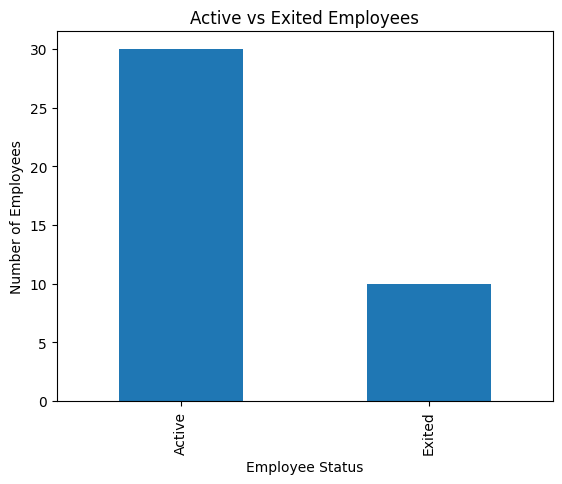

In [20]:
#Create an employee status chart

status_counts.plot(kind="bar")

plt.title("Active vs Exited Employees")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")

plt.show()

In [21]:
#Create a department-wise exits bar chart

department_exits = department_summary["Exits"]

print(department_exits)

Department
Finance                   1
Human Resources           2
Human Resourses           0
Information Technology    2
Marketing                 2
Not Recorded              0
Operations                0
Sales                     3
Name: Exits, dtype: int64


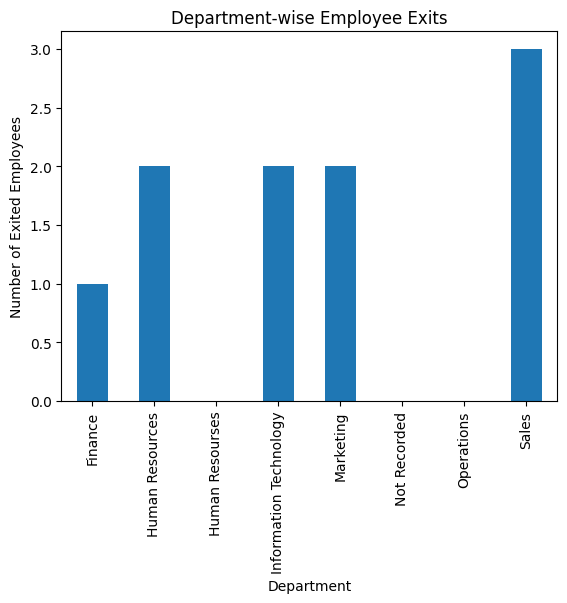

In [22]:
department_exits.plot(kind="bar")

plt.title("Department-wise Employee Exits")
plt.xlabel("Department")
plt.ylabel("Number of Exited Employees")

plt.show()

In [23]:
department_exit_percentage = department_summary["Exit_Percentage"]

print(department_exit_percentage)

Department
Finance                   16.7
Human Resources           28.6
Human Resourses            0.0
Information Technology    28.6
Marketing                 40.0
Not Recorded               0.0
Operations                 0.0
Sales                     50.0
Name: Exit_Percentage, dtype: float64


In [24]:
#actual analysis
#Find the highest and lowest exit departments

highest_exit = department_summary["Exit_Percentage"].idxmax()
lowest_exit = department_summary["Exit_Percentage"].idxmin()

print("Highest exit department:", highest_exit)
print("Lowest exit department:", lowest_exit)

print("\nDepartment-wise summary:")
print(department_summary)

Highest exit department: Sales
Lowest exit department: Human Resourses

Department-wise summary:
                        Total_Employees  Exits  Exit_Percentage
Department                                                     
Finance                               6      1             16.7
Human Resources                       7      2             28.6
Human Resourses                       1      0              0.0
Information Technology                7      2             28.6
Marketing                             5      2             40.0
Not Recorded                          1      0              0.0
Operations                            7      0              0.0
Sales                                 6      3             50.0


In [25]:
#data standardization.we see some mistakes like human resources and human resourses appeared and not recorded appeared.
df["Department"] = df["Department"].str.strip()

df["Department"] = df["Department"].replace({
    "Human Resourses": "Human Resources",
    "human resources": "Human Resources",
    "HUMAN RESOURCES": "Human Resources",
    "Not Recorded": "Unknown"
})

In [26]:
df["Department"].unique()

array(['Human Resources', 'Information Technology', 'Sales', 'Marketing',
       'Operations', 'Finance', 'Unknown'], dtype=object)

In [27]:
#Recalculate department-wise exit analysis

department_summary = df.groupby("Department").agg(
    Total_Employees=("Employee_ID", "count"),
    Exits=("Employee_Status", lambda x: (x == "Exited").sum())
)

department_summary["Exit_Percentage"] = (
    department_summary["Exits"] /
    department_summary["Total_Employees"] * 100
).round(1)

department_summary

,Total_Employees,Exits,Exit_Percentage
Department,,,
Finance,6,1,16.7
Human Resources,8,2,25.0
Information Technology,7,2,28.6
Marketing,5,2,40.0
Operations,7,0,0.0
Sales,6,3,50.0
Unknown,1,0,0.0


In [28]:
lowest_percentage = department_summary["Exit_Percentage"].min()

lowest_departments = department_summary[
    department_summary["Exit_Percentage"] == lowest_percentage
]

print(lowest_departments)

            Total_Employees  Exits  Exit_Percentage
Department                                         
Operations                7      0              0.0
Unknown                   1      0              0.0


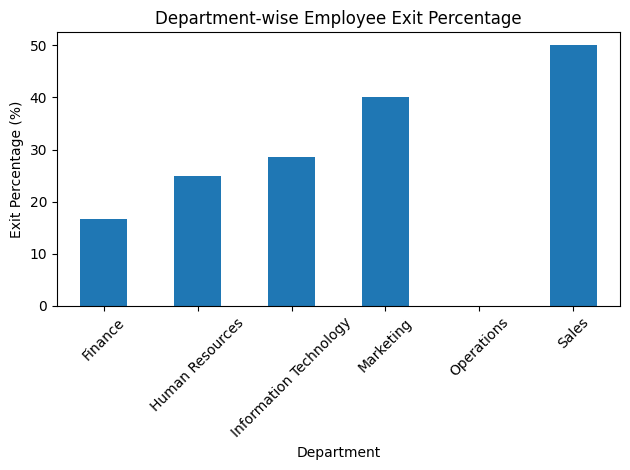

In [29]:
import matplotlib.pyplot as plt

# Exclude Unknown department from comparison
chart_data = department_summary.drop(index="Unknown", errors="ignore")

chart_data["Exit_Percentage"].plot(kind="bar")

plt.title("Department-wise Employee Exit Percentage")
plt.xlabel("Department")
plt.ylabel("Exit Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
#actual analysis

highest_percentage = chart_data["Exit_Percentage"].max()
lowest_percentage = chart_data["Exit_Percentage"].min()

highest_departments = chart_data[
    chart_data["Exit_Percentage"] == highest_percentage
]

lowest_departments = chart_data[
    chart_data["Exit_Percentage"] == lowest_percentage
]

print("Highest exit percentage:")
print(highest_departments)

print("\nLowest exit percentage:")
print(lowest_departments)

Highest exit percentage:
            Total_Employees  Exits  Exit_Percentage
Department                                         
Sales                     6      3             50.0

Lowest exit percentage:
            Total_Employees  Exits  Exit_Percentage
Department                                         
Operations                7      0              0.0


In [32]:
#Create an overall HR summary

overall_summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Active Employees",
        "Exited Employees",
        "Sample Exit Percentage"
    ],
    "Value": [
        total_employees,
        active_employees,
        exited_employees,
        round(exit_percentage, 1)
    ]
})

overall_summary

,Metric,Value
0,Total Employees,40.0
1,Active Employees,30.0
2,Exited Employees,10.0
3,Sample Exit Percentage,25.0


In [33]:
#Export all three tables into Excel

with pd.ExcelWriter("Employee_Turnover_Analysis.xlsx") as writer:

    df.to_excel(
        writer,
        sheet_name="Turnover_Data",
        index=False
    )

    overall_summary.to_excel(
        writer,
        sheet_name="Overall_Summary",
        index=False
    )

    department_summary.to_excel(
        writer,
        sheet_name="Department_Analysis"
    )

print("Excel workbook created successfully!")

Excel workbook created successfully!


In [34]:
#Download the Excel workbook

from google.colab import files

files.download("Employee_Turnover_Analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>